# Proyecto completo de machine learning — Gasto turístico por país de destino

Máster de FP en Inteligencia Artificial y Big Data.

Este cuaderno recorre un proyecto completo de aprendizaje automático con la estadística del INE *Distribución del gasto turístico y gasto medio diario realizado según país de destino* (tabla 58692). El hilo es el mismo que en un proyecto de regresión clásico: entender el problema, explorar los datos, dejarlos listos para un algoritmo, comparar modelos y valorar el error con honestidad.

## Imagen general / problema a resolver

La consultora **Destino Norte** quiere anticipar cuánto gastan, en un mes concreto, los residentes en España cuando viajan a un país. Con esa cifra puede orientar campañas, prever temporadas fuertes y detectar destinos cuyo volumen se sale de lo habitual.

Cada fila que vamos a modelar describe un **país de destino** en un **mes**. El valor que queremos predecir es el **gasto turístico** de ese mes, en euros.

Los datos están etiquetados (el INE publica la cifra real) y la salida es un número, así que el problema es de **aprendizaje supervisado** y, en concreto, de **regresión múltiple**: usamos varias características a la vez (el país, el mes y el año).

En regresión una medida habitual del error es la **raíz del error cuadrático medio**, en inglés *Root Mean Square Error* (**RMSE**).

$$RMSE(X, h)=\sqrt{\frac{1}{m}\sum_{i=1}^{m}\left(h(x^{(i)})-y^{(i)}\right)^{2}}$$

$m$ es el número de instancias (aquí, pares país-mes).

$x^{(i)}$ es el vector de características de la instancia $i$, sin la etiqueta. En este proyecto esas características son el país, el mes y el año.

$y^{(i)}$ es el gasto turístico real de esa instancia, en euros.

$h$ es la función de predicción. Cuando recibe $x^{(i)}$ devuelve $\hat{y}^{(i)}=h(x^{(i)})$.

Por ejemplo, si en un mes el gasto real en un destino fue de 120 millones de euros y el modelo anuncia 105 millones, el error de ese caso es $105-120=-15$ millones. El RMSE junta todos esos errores, da más peso a los errores grandes y se expresa en las mismas unidades que $y$: euros.

## 1. Obtención de datos

**Fuente.** Instituto Nacional de Estadística (INE), INEbase, tabla **58692**:

- Título: *Distribución del gasto turístico y gasto medio diario realizado según país de destino*.
- Descripción oficial: distribución del gasto realizado por los residentes en España en sus visitas al extranjero, según país de destino.
- Periodicidad: mensual. Unidades: euros.
- Ficha de la tabla: [https://www.ine.es/jaxiT3/Tabla.htm?t=58692](https://www.ine.es/jaxiT3/Tabla.htm?t=58692)
- Descarga usada: `58692.csv` (CSV separado por `;`, el formato con el que el INE exporta esta tabla).

**Cómo se han obtenido.** No proceden de un sensor ni de un experimento propio. Son una estadística oficial compilada y publicada por el INE. El fichero trae el producto cartesiano país × magnitud × mes; cuando el INE no publica la cifra (no hay muestra suficiente o rige el secreto estadístico) el valor aparece como `.` o vacío.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 20)

In [2]:
ruta_csv = Path("58692.csv")
if not ruta_csv.exists():
    raise FileNotFoundError(
        "No encuentro 58692.csv junto a este cuaderno. "
        "En Colab, súbelo al directorio de trabajo."
    )

bruto = pd.read_csv(ruta_csv, sep=";")
bruto = bruto.rename(columns={
    "Países": "pais",
    "Gasto Turístico": "tipo_gasto",
    "Periodo": "periodo",
    "Total": "total",
})
bruto.head(8)

,pais,tipo_gasto,periodo,total
0,Albania,Gasto turístico,2026M06,5.650.907
1,Albania,Gasto turístico,2026M05,3.362.842
2,Albania,Gasto turístico,2026M04,3.296.078
3,Albania,Gasto turístico,2026M03,1.062.550
4,Albania,Gasto turístico,2026M02,750.060
5,Albania,Gasto turístico,2026M01,1.131.984
6,Albania,Gasto turístico,2025M12,868.849
7,Albania,Gasto turístico,2025M11,1.170.162


In [3]:
print("Filas y columnas:", bruto.shape)
print("Países:", bruto["pais"].nunique())
print("Magnitudes:", bruto["tipo_gasto"].unique().tolist())
periodos = sorted(bruto["periodo"].unique(), key=lambda p: (int(p[:4]), int(p[5:])))
print("Primer periodo:", periodos[0], "  Último:", periodos[-1])
print("Periodos distintos:", len(periodos))

Filas y columnas: (44550, 4)
Países: 165
Magnitudes: ['Gasto turístico', 'Gasto medio turístico', 'Gasto tarjeta']
Primer periodo: 2019M01   Último: 2026M06
Periodos distintos: 90


## 2. Descripción de los datos

El CSV viene en formato **largo**: una fila por cada combinación de país, magnitud y mes. Por eso 165 países × 3 magnitudes × 90 meses dan 44.550 filas.

| Atributo en el fichero | Nombre en el cuaderno | Qué significa |
| --- | --- | --- |
| `Países` | `pais` | País de destino del viaje de los residentes en España. Hay 165 países, agrupados en el fichero por continente. |
| `Gasto Turístico` | `tipo_gasto` | Qué magnitud trae esa fila. No es el importe: es el nombre de la serie. |
| `Periodo` | `periodo` | Mes, con el formato del INE `AAAAMMM` (por ejemplo `2024M08` es agosto de 2024). Cubre de enero de 2019 a junio de 2026. |
| `Total` | `total` | Importe en euros, todavía como texto. El INE usa el punto como separador de miles (`5.650.907`) y la coma como separador decimal en el gasto medio (`272,72`). Un punto solo (`.`) o una celda vacía significan dato no publicado. |

Las tres magnitudes, todas en euros, son:

- **Gasto turístico**: gasto total del mes en ese destino.
- **Gasto medio turístico**: gasto medio diario. Lo dice el título de la tabla y encaja con la escala (la mayor parte de los valores está entre 100 y 250 euros, no en miles). En el cuaderno lo llamamos `gasto_medio_diario`.
- **Gasto tarjeta**: gasto pagado con tarjeta en ese destino y mes.

Un mismo país y mes ocupa tres filas, una por magnitud. Para modelar hace falta pasar a formato **ancho**: una fila por país y mes, con una columna para cada magnitud.

## 3. Exploración y visualización de los datos

Primero se convierte el texto del INE a número y se cuentan los huecos. Después se reorganiza la tabla y se mira la forma de cada magnitud, el calendario y la relación entre series.

In [4]:
bruto["tipo_gasto"].value_counts()

tipo_gasto
Gasto turístico          14850
Gasto medio turístico    14850
Gasto tarjeta            14850
Name: count, dtype: int64

In [5]:
def euros_ine(tipo, texto):
    """Convierte un importe del INE a float.

    El gasto medio usa coma decimal y, a veces, punto de miles (1.161,87).
    El gasto total y el gasto con tarjeta usan punto de miles (5.650.907).
    '.' y el vacío son datos no publicados.
    """
    if pd.isna(texto):
        return np.nan
    s = str(texto).strip()
    if s in {"", "."}:
        return np.nan
    if tipo == "Gasto medio turístico":
        return float(s.replace(".", "").replace(",", "."))
    return float(s.replace(".", ""))


largo = bruto.copy()
largo["euros"] = [
    euros_ine(tipo, texto)
    for tipo, texto in zip(largo["tipo_gasto"], largo["total"])
]
print("Valores no publicados:", int(largo["euros"].isna().sum()), "de", len(largo))
largo[["pais", "tipo_gasto", "periodo", "total", "euros"]].head(6)

Valores no publicados: 15987 de 44550


,pais,tipo_gasto,periodo,total,euros
0,Albania,Gasto turístico,2026M06,5.650.907,5650907.0
1,Albania,Gasto turístico,2026M05,3.362.842,3362842.0
2,Albania,Gasto turístico,2026M04,3.296.078,3296078.0
3,Albania,Gasto turístico,2026M03,1.062.550,1062550.0
4,Albania,Gasto turístico,2026M02,750.060,750060.0
5,Albania,Gasto turístico,2026M01,1.131.984,1131984.0


In [6]:
ejemplo = largo[(largo["pais"] == "Albania") & (largo["periodo"] == "2026M06")]
ejemplo[["tipo_gasto", "total", "euros"]]

,tipo_gasto,total,euros
0,Gasto turístico,5.650.907,5650907.00
90,Gasto medio turístico,"272,72",272.72
180,Gasto tarjeta,1.977.547,1977547.00


In [7]:
gasto = (
    largo.pivot(index=["pais", "periodo"], columns="tipo_gasto", values="euros")
    .reset_index()
    .rename(columns={
        "Gasto turístico": "gasto_turistico",
        "Gasto medio turístico": "gasto_medio_diario",
        "Gasto tarjeta": "gasto_tarjeta",
    })
)
gasto.columns.name = None

gasto["anio"] = gasto["periodo"].str.slice(0, 4).astype(int)
gasto["mes"] = gasto["periodo"].str.slice(5).astype(int)
gasto["fecha"] = pd.to_datetime(
    gasto["anio"].astype(str) + "-" + gasto["mes"].astype(str).str.zfill(2) + "-01"
)

nombres_mes = {
    1: "enero", 2: "febrero", 3: "marzo", 4: "abril",
    5: "mayo", 6: "junio", 7: "julio", 8: "agosto",
    9: "septiembre", 10: "octubre", 11: "noviembre", 12: "diciembre",
}
gasto["mes_nombre"] = gasto["mes"].map(nombres_mes)
gasto = gasto.sort_values(["pais", "fecha"]).reset_index(drop=True)

print("Combinaciones país-mes:", len(gasto))
print("Con gasto publicado:", int(gasto["gasto_turistico"].notna().sum()))
gasto.head()

Combinaciones país-mes: 14850
Con gasto publicado: 9521


,pais,periodo,gasto_medio_diario,gasto_tarjeta,gasto_turistico,anio,mes,fecha,mes_nombre
0,Afganistán,2019M01,NaN,NaN,NaN,2019,1,2019-01-01,enero
1,Afganistán,2019M02,NaN,NaN,NaN,2019,2,2019-02-01,febrero
2,Afganistán,2019M03,NaN,NaN,NaN,2019,3,2019-03-01,marzo
3,Afganistán,2019M04,NaN,NaN,NaN,2019,4,2019-04-01,abril
4,Afganistán,2019M05,NaN,NaN,NaN,2019,5,2019-05-01,mayo


In [8]:
gasto[["gasto_turistico", "gasto_medio_diario", "gasto_tarjeta"]].describe()

,gasto_turistico,gasto_medio_diario,gasto_tarjeta
count,9.521000e+03,9521.000000,9.521000e+03
mean,1.201194e+07,179.607223,4.829440e+06
std,3.872597e+07,116.454124,1.370450e+07
min,9.842000e+03,7.450000,8.008000e+03
25%,3.893120e+05,108.300000,2.068020e+05
50%,1.540490e+06,152.000000,7.588880e+05
75%,6.447251e+06,214.830000,3.007174e+06
max,7.508298e+08,1316.330000,2.014211e+08


La escala de las tres columnas no tiene nada que ver. El gasto total medio de un país-mes ronda los 12 millones de euros, pero la mediana está en torno a 1,5 millones: unos pocos destinos (los grandes mercados europeos y algún destino lejano muy visitado) concentran el volumen y estiran la media. El gasto medio diario vive en otra escala, alrededor de 100-250 euros.

In [9]:
huecos = gasto[["gasto_turistico", "gasto_medio_diario", "gasto_tarjeta"]].isna()
print("Celdas vacías por magnitud:")
print(huecos.sum())
print()
print("Los tres huecos coinciden en la misma fila:", bool((huecos.sum(axis=1).isin([0, 3])).all()))

tasa_huecos = huecos["gasto_turistico"].groupby(gasto["anio"]).mean().mul(100).round(1)
tasa_huecos

Celdas vacías por magnitud:
gasto_turistico       5329
gasto_medio_diario    5329
gasto_tarjeta         5329
dtype: int64

Los tres huecos coinciden en la misma fila: True


anio
2019    24.2
2020    64.4
2021    51.5
2022    28.0
2023    29.1
2024    28.7
2025    27.8
2026    30.8
Name: gasto_turistico, dtype: float64

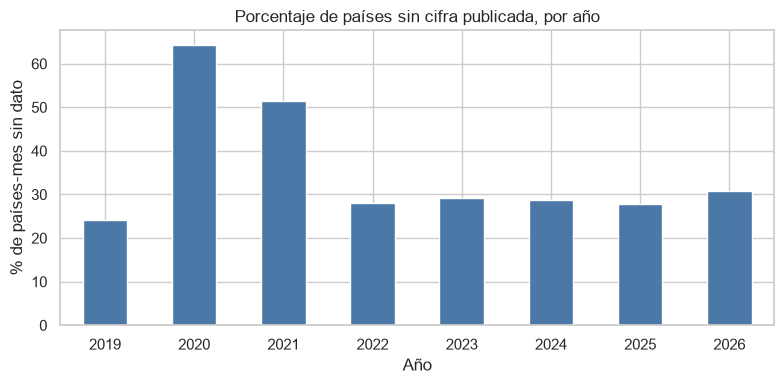

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
tasa_huecos.plot(kind="bar", color="#4C78A8", ax=ax)
ax.set_title("Porcentaje de países sin cifra publicada, por año")
ax.set_xlabel("Año")
ax.set_ylabel("% de países-mes sin dato")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

Los huecos no están repartidos al azar. En 2020 no se publica cerca del 64 % de los países-mes y en 2021 en torno a la mitad; en el resto de años el hueco queda entre el 24 % y el 31 %. Son, sobre todo en 2020 y 2021, los años de restricciones a los viajes. El INE deja de publicar el cruce país-mes cuando no puede estimarlo. Esas filas no se pueden inventar con una mediana: no hay un "gasto típico" que valga a la vez para Francia en agosto y para un país con el que casi no hay viajes.

Además, el hueco es el mismo en las tres magnitudes. O el INE publica el mes completo de un destino, o no publica ninguna de las tres cifras.

In [11]:
regiones = {
    "Europa": [
        "Albania", "Alemania", "Andorra", "Armenia", "Austria", "Belarús", "Bélgica",
        "Bosnia y Herzegovina", "Bulgaria", "Chipre", "Croacia", "Dinamarca", "Eslovenia",
        "Estonia", "Francia", "Finlandia", "Georgia", "Grecia", "Hungría", "Irlanda",
        "Islandia", "Italia", "Letonia", "Liechtenstein", "Lituania", "Luxemburgo",
        "Macedonia del Norte", "Malta", "Moldavia", "Mónaco", "Montenegro", "Noruega",
        "Países Bajos", "Polonia", "Portugal", "Reino Unido", "República Checa",
        "República Eslovaca", "Rumanía", "Rusia", "San Marino", "Santa Sede", "Serbia",
        "Suecia", "Suiza", "Turquía", "Ucrania",
    ],
    "África": [
        "Angola", "Argelia", "Benin", "Botswana", "Burkina Faso", "Cabo Verde", "Camerún",
        "Chad", "Costa de Marfil", "Djibouti", "Egipto", "Etiopía", "Gabón", "Gambia",
        "Ghana", "Guinea", "Guinea-Bissau", "Guinea Ecuatorial", "Kenia", "Madagascar",
        "Malawi", "Mali", "Marruecos", "Mauricio", "Mauritania", "Mozambique", "Namibia",
        "Níger", "Nigeria", "República Democrática del Congo", "Ruanda", "Senegal",
        "Seychelles", "Sierra Leona", "Sudáfrica", "Swazilandia", "Tanzania", "Togo",
        "Túnez", "Uganda", "Zambia", "Zimbabwe",
    ],
    "América": [
        "Antigua y Barbuda", "Argentina", "Bahamas", "Barbados", "Belice", "Bolivia",
        "Brasil", "Canadá", "Chile", "Colombia", "Costa Rica", "Cuba", "Ecuador",
        "El Salvador", "Estados Unidos de América", "Granada", "Guatemala", "Haití",
        "Honduras", "Jamaica", "México", "Nicaragua", "Panamá", "Paraguay", "Perú",
        "República Dominicana", "San Vicente y las Granadinas", "Santa Lucía", "Surinam",
        "Trinidad y Tobago", "Uruguay", "Venezuela", "Groenlandia",
    ],
    "Asia": [
        "Afganistán", "Arabia Saudí", "Azerbaiyán", "Bahréin", "Bangladesh", "Bhután",
        "Camboya", "China", "Corea", "Emiratos Árabes Unidos", "Filipinas", "India",
        "Indonesia", "Iraq", "Israel", "Japón", "Jordania", "Kazajstán", "Kirguistán",
        "Kuwait", "Laos", "Líbano", "Malasia", "Maldivas", "Mongolia", "Myanmar", "Nepal",
        "Omán", "Pakistán", "Palestina", "Qatar", "Singapur", "Sri Lanka", "Tailandia",
        "Tayikistán", "Turkmenistán", "Uzbekistán", "Vietnam",
    ],
    "Oceanía": ["Australia", "Fiji", "Islas Cook", "Nueva Zelanda", "Palaos"],
}
pais_a_region = {pais: region for region, paises in regiones.items() for pais in paises}
gasto["region"] = gasto["pais"].map(pais_a_region)

sin_region = sorted(set(gasto["pais"]) - set(pais_a_region))
print("Países sin región asignada:", sin_region if sin_region else "ninguno")
print("Países por región:")
gasto.drop_duplicates("pais")["region"].value_counts()

Países sin región asignada: ninguno
Países por región:


region
Europa     47
África     42
Asia       38
América    33
Oceanía     5
Name: count, dtype: int64

La región no viene en el fichero. Se construye a partir del país, siguiendo el orden continental con el que el INE lista los destinos (Europa, África, América, Asia y Oceanía; Groenlandia queda con América). Sirve para explorar. El modelo, más adelante, usa el país: dentro de un mismo continente conviven Portugal y San Marino, y su gasto mensual no se parece.

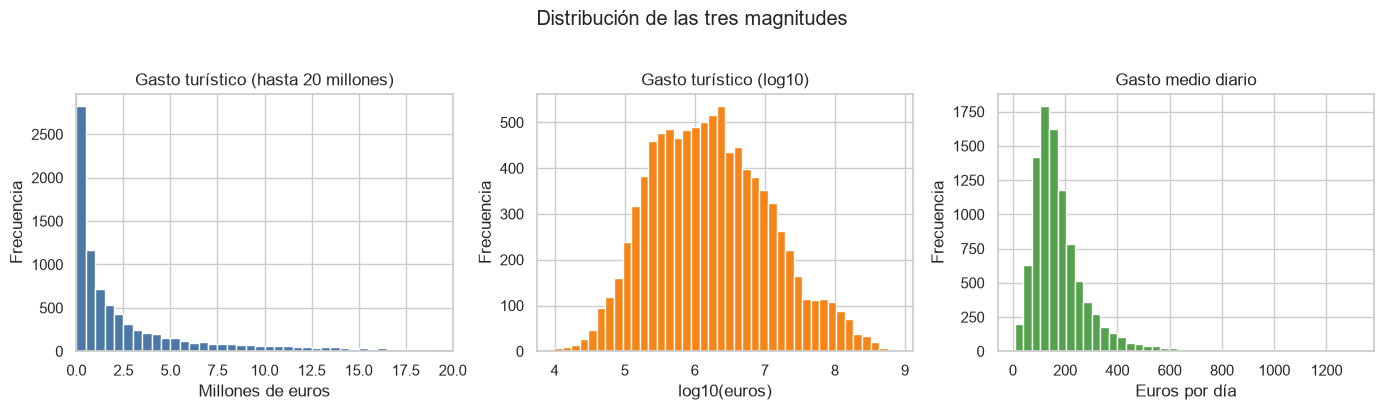

In [ ]:
observado = gasto.dropna(subset=["gasto_turistico"]).copy()
observado["log10_gasto"] = np.log10(observado["gasto_turistico"])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(
    observado["gasto_turistico"] / 1e6,
    bins=40,
    range=(0, 20),
    color="#4C78A8",
)
axes[0].set_xlim(0, 20)
axes[0].set_title("Gasto turístico (hasta 20 millones)")
axes[0].set_xlabel("Millones de euros")
axes[1].hist(observado["log10_gasto"], bins=40, color="#F58518")
axes[1].set_title("Gasto turístico (log10)")
axes[1].set_xlabel("log10(euros)")
axes[2].hist(observado["gasto_medio_diario"].dropna(), bins=40, color="#54A24B")
axes[2].set_title("Gasto medio diario")
axes[2].set_xlabel("Euros por día")
for ax in axes:
    ax.set_ylabel("Frecuencia")
fig.suptitle("Distribución de las tres magnitudes", y=1.02)
plt.tight_layout()
plt.show()

El gasto total está muy sesgado a la derecha: casi todas las observaciones son pequeñas y unas pocas son enormes. El primer histograma corta el eje en 20 millones de euros para que se vea esa mayoría; la cola, hasta más de 750 millones, queda en el panel logarítmico, donde la forma se abre y se parece más a una campana ancha. El gasto medio diario también tiene cola (hay destinos y meses con medias de más de 1.000 euros, casi siempre países con muy pocos viajeros), pero su centro está estable cerca de 150 euros.

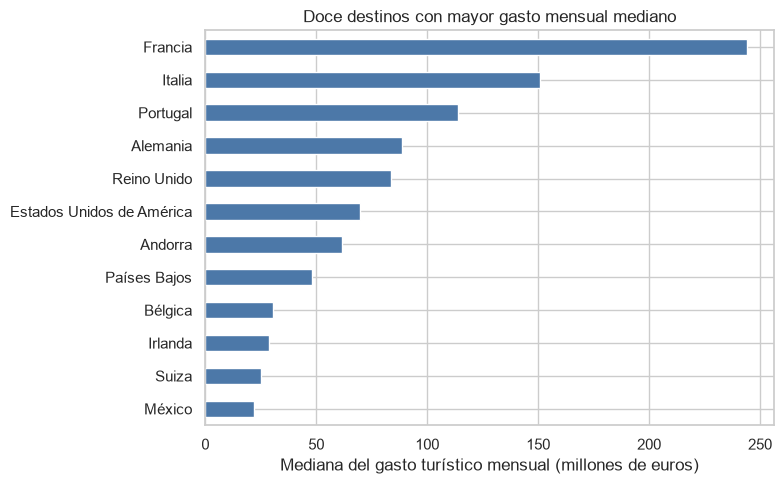

In [13]:
mediana_pais = (
    observado.groupby("pais")["gasto_turistico"].median().sort_values(ascending=False).head(12) / 1e6
)
fig, ax = plt.subplots(figsize=(8, 5))
mediana_pais.sort_values().plot(kind="barh", color="#4C78A8", ax=ax)
ax.set_title("Doce destinos con mayor gasto mensual mediano")
ax.set_xlabel("Mediana del gasto turístico mensual (millones de euros)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

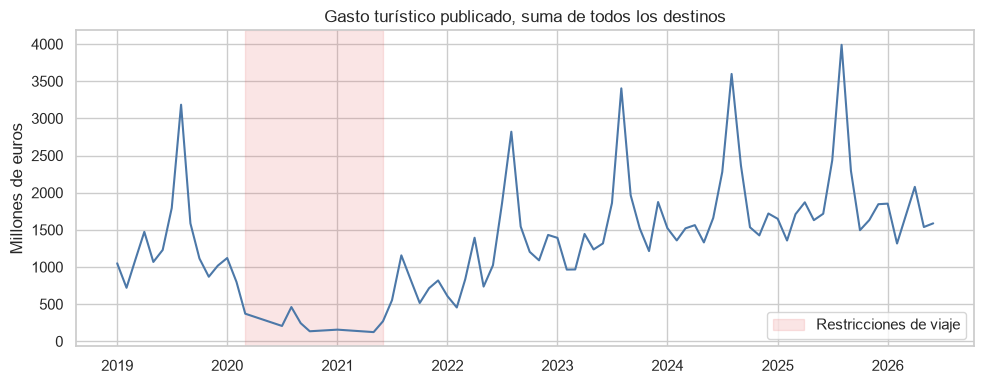

In [14]:
total_publicado = observado.groupby("fecha")["gasto_turistico"].sum() / 1e6
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(total_publicado.index, total_publicado.values, color="#4C78A8")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color="#E45756", alpha=0.15, label="Restricciones de viaje")
ax.set_title("Gasto turístico publicado, suma de todos los destinos")
ax.set_ylabel("Millones de euros")
ax.set_xlabel("")
ax.legend()
plt.tight_layout()
plt.show()

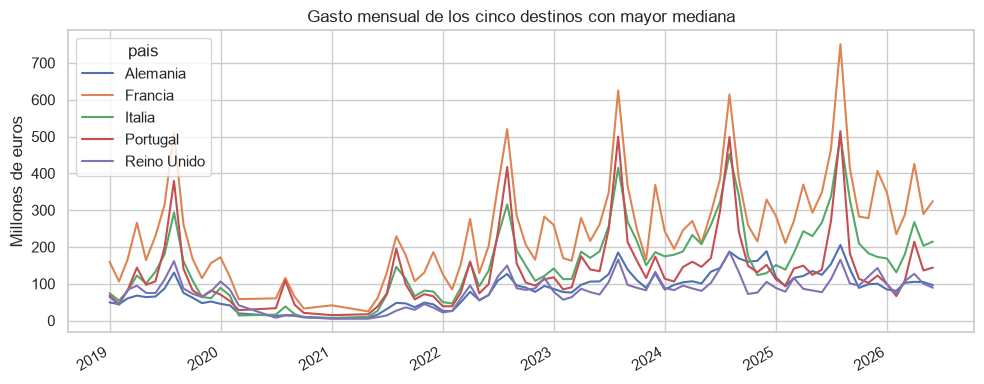

In [15]:
top5 = observado.groupby("pais")["gasto_turistico"].median().nlargest(5).index
serie_top = (
    observado[observado["pais"].isin(top5)]
    .pivot_table(index="fecha", columns="pais", values="gasto_turistico", aggfunc="first")
    / 1e6
)
fig, ax = plt.subplots(figsize=(10, 4))
serie_top.plot(ax=ax)
ax.set_title("Gasto mensual de los cinco destinos con mayor mediana")
ax.set_ylabel("Millones de euros")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

El calendario manda. Cada verano el gasto total se dispara y en el invierno europeo baja; 2020 y la primera mitad de 2021 rompen esa onda. Los destinos grandes repiten el mismo dibujo año tras año, cada uno a su nivel: Francia, Italia o Portugal no intercambian el sitio con un destino pequeño. Esa repetición es lo que un modelo puede aprender.

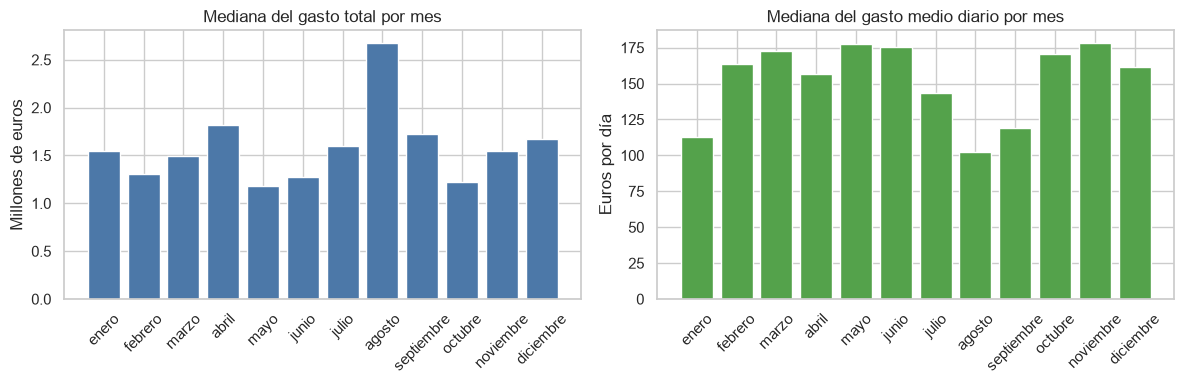

In [16]:
orden_mes = list(nombres_mes.values())
por_mes = (
    observado.groupby("mes_nombre")[["gasto_turistico", "gasto_medio_diario"]]
    .median()
    .reindex(orden_mes)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(orden_mes, por_mes["gasto_turistico"] / 1e6, color="#4C78A8")
axes[0].set_title("Mediana del gasto total por mes")
axes[0].set_ylabel("Millones de euros")
axes[1].bar(orden_mes, por_mes["gasto_medio_diario"], color="#54A24B")
axes[1].set_title("Mediana del gasto medio diario por mes")
axes[1].set_ylabel("Euros por día")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Agosto concentra el gasto total (más viajes, estancias más largas) y, a la vez, es de los meses con **menor** gasto medio diario. Enero también tiene un diario bajo. El viajero de verano no gasta más cada día: viaja más gente y se queda más tiempo. Son dos fenómenos distintos y por eso el gasto diario no es un sustituto del gasto total.

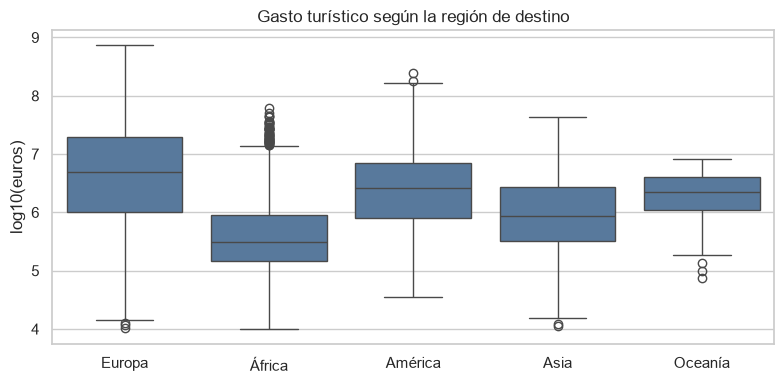

region
Europa     124.2
África     155.9
América    169.6
Asia       193.0
Oceanía    219.7
Name: gasto_medio_diario, dtype: float64

In [17]:
orden_region = ["Europa", "África", "América", "Asia", "Oceanía"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(
    data=observado,
    x="region",
    y="log10_gasto",
    order=orden_region,
    ax=ax,
    color="#4C78A8",
)
ax.set_title("Gasto turístico según la región de destino")
ax.set_xlabel("")
ax.set_ylabel("log10(euros)")
plt.tight_layout()
plt.show()

observado.groupby("region")["gasto_medio_diario"].median().reindex(orden_region).round(1)

### Correlaciones

Con tres magnitudes numéricas la matriz de correlación es pequeña. Aun así conviene mirarla antes de elegir el target y las variables de entrada: una correlación cercana a 1 entre dos columnas significa que, a efectos prácticos, son la misma información.

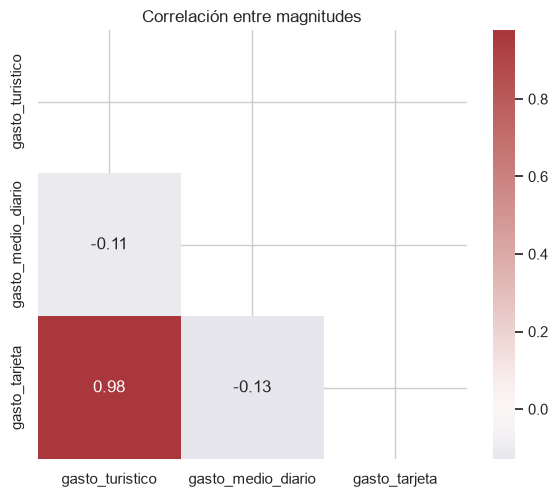

In [18]:
columnas_importe = ["gasto_turistico", "gasto_medio_diario", "gasto_tarjeta"]
corr = observado[columnas_importe].corr()

mascara = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    square=True,
    center=0,
    cmap="vlag",
    ax=ax,
)
ax.set_title("Correlación entre magnitudes")
plt.tight_layout()
plt.show()

La lectura de esa matriz decide el diseño del modelo:

- **Gasto turístico y gasto con tarjeta se mueven juntos** (correlación en torno a 0,98). El pago con tarjeta acompaña al volumen total; no cuenta una historia distinta. Usarlo como predictor sería casi equivalente a darle al modelo la respuesta, porque el INE publica las dos cifras a la vez.
- **El gasto medio diario apenas está relacionado con el volumen** (correlación débil y negativa). Un destino puede mover mucho dinero con un gasto diario moderado, si recibe a mucha gente.

Por eso el modelo no recibe ni el gasto con tarjeta ni el gasto medio diario. Las entradas son hechos que se conocen antes de que el INE cierre el mes: **a qué país se viaja, en qué mes y en qué año**.

## 4. Exposición del objetivo

A la vista de la exploración, el target es:

**`gasto_turistico`**: euros gastados por los residentes en España en un país de destino durante un mes.

Se descarta predecir el gasto medio diario como objetivo principal. Interesa para describir el viaje (y por eso se ha explorado), pero la pregunta de la consultora es de volumen: cuánto dinero se mueve hacia ese destino. El diario, además, es más ruidoso en los países con pocos viajeros, donde una media de un mes puede pasar de 100 a más de 1.000 euros sin que cambie el mercado.

Queda así definido el problema:

- Supervisado, porque el INE ya etiquetó cada país-mes.
- Regresión múltiple, porque la salida es un número y entran el país, el mes y el año.
- Métrica principal: **RMSE en euros**. Se acompaña con **R²** (proporción de varianza explicada) y con el **error absoluto mediano**, que no se deja arrastrar tanto por Francia o Italia y dice mejor qué error es habitual en un destino cualquiera.

## 5. Preparación de los datos para los algoritmos

### Atributos que entran en el modelo

De la exploración salen tres predictores:

- `pais`, categórico, con muchas clases. Es la pieza que distingue un destino grande de uno pequeño.
- `mes`, categórico. Agosto no es "el doble" que abril, así que el número de mes no se deja como una recta: se trata como categoría.
- `anio`, numérico. Recoge la tendencia entre 2019 y 2026 (recuperación posterior a las restricciones, precios, hábito de viaje).

`region` se queda en el análisis y no entra en la matriz del modelo: es una función exacta del país, y meter las dos cosas a la vez duplicaría la información.

No hace falta escalar. El país y el mes van a quedar como columnas de ceros y unos, y el año solo se mueve entre 2019 y 2026. Los algoritmos que vamos a usar (regresión lineal, árbol y bosque) no calculan distancias entre filas, que es donde un escalado cambia el resultado.

### Gestión de nulos

Hay tres formas habituales de tratar un hueco. Aquí el hueco está en el propio target, no en un predictor:

1. **Quitar las filas sin gasto publicado.** Es la opción que se adopta. Sin la etiqueta no se puede entrenar ni evaluar, y el patrón de los huecos (secreto estadístico, meses sin viajes) no es el de un valor "olvidado al azar".
2. **Quitar la columna.** No tiene sentido: esa columna es justo lo que queremos predecir.
3. **Rellenar con la mediana.** Fabricaría una respuesta. La mediana global (alrededor de un millón y medio de euros) no describe ni un agosto en Italia ni un febrero en un destino con pocos viajes.

Los predictores `pais`, `mes` y `anio` están completos en todas las filas.

In [19]:
modelo = gasto.dropna(subset=["gasto_turistico"])[["pais", "mes_nombre", "anio", "gasto_turistico"]].copy()
modelo = modelo.rename(columns={"mes_nombre": "mes"})
print("Instancias con target publicado:", len(modelo))
print("Países que aparecen al menos una vez:", modelo["pais"].nunique())
print("Años:", sorted(modelo["anio"].unique().tolist()))
modelo.head()

Instancias con target publicado: 9521
Países que aparecen al menos una vez: 139
Años: [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


,pais,mes,anio,gasto_turistico
90,Albania,enero,2019,127999.0
91,Albania,febrero,2019,114893.0
92,Albania,marzo,2019,153657.0
93,Albania,abril,2019,254721.0
94,Albania,mayo,2019,265167.0


### Conversión de categorías a números

La regresión lineal, el árbol y el bosque necesitan números. `pais` y `mes` no tienen un orden que convenga codificar como 1, 2, 3… (Francia no es "más país" que Alemania, y diciembre no es doce veces enero).

Se usa codificación **one-hot**: una columna de 0 o 1 por cada país y por cada mes. `anio` ya es un número y se queda como está.

In [20]:
codificado = pd.get_dummies(modelo, columns=["pais", "mes"], dtype=int)
print("Columnas tras la codificación:", codificado.shape[1])
codificado.head()

Columnas tras la codificación: 153


,anio,gasto_turistico,pais_Albania,pais_Alemania,pais_Andorra,pais_Angola,pais_Antigua y Barbuda,pais_Arabia Saudí,pais_Argelia,pais_Argentina,...,mes_diciembre,mes_enero,mes_febrero,mes_julio,mes_junio,mes_marzo,mes_mayo,mes_noviembre,mes_octubre,mes_septiembre
90,2019,127999.0,1,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
91,2019,114893.0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
92,2019,153657.0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
93,2019,254721.0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
94,2019,265167.0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


### Mezcla de datos y partición

Dentro del fichero las filas vienen ordenadas por país y, dentro del país, por mes. Si se entrenara siguiendo ese orden, un bloque de validación podría contener solo un grupo de destinos. Se baraja el conjunto antes de separarlo.

La separación de trabajo, la misma que en un proyecto de regresión estándar, es:

- 80 % entrenamiento
- 20 % prueba

El conjunto de prueba no se usa para elegir el modelo ni para ajustar hiperparámetros. Como estas filas además tienen fecha, más adelante se repite la evaluación con un corte temporal (entrenar con 2019-2024 y probar en 2025-2026). Ese segundo examen responde a una pregunta distinta: si el modelo sirve para un año que todavía no ha visto.

In [21]:
barajado = codificado.sample(frac=1, random_state=42)
barajado.head()

,anio,gasto_turistico,pais_Albania,pais_Alemania,pais_Andorra,pais_Angola,pais_Antigua y Barbuda,pais_Arabia Saudí,pais_Argelia,pais_Argentina,...,mes_diciembre,mes_enero,mes_febrero,mes_julio,mes_junio,mes_marzo,mes_mayo,mes_noviembre,mes_octubre,mes_septiembre
13096,2022,7160862.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
12676,2025,791358.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
5915,2024,56578.0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
7841,2019,14241.0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
11492,2024,10338599.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


In [22]:
y = barajado["gasto_turistico"]
X = barajado.drop(columns=["gasto_turistico"])
X.shape, y.shape

((9521, 152), (9521,))

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Entrenamiento:", X_train.shape[0], "  Prueba:", X_test.shape[0])

Entrenamiento: 7616   Prueba: 1905


## 6. Entrenamiento del modelo y comprobación del rendimiento

Se comparan tres regresores. En los tres se muestra primero el error **sobre los datos con los que se acaba de entrenar** (una cifra optimista) y después una **validación cruzada** sobre el conjunto de entrenamiento.

### Validación cruzada

La validación cruzada estima cómo se comportará el modelo con datos que no ha memorizado, sin tocar todavía el conjunto de prueba.

1. El entrenamiento se divide en **K partes** de tamaño parecido. Aquí K = 3, para que la comparación no se alargue.
2. Se entrena con K − 1 partes y se mide el error en la parte restante.
3. Se repite hasta que cada parte haya sido la de validación.
4. Se promedian el RMSE y el R² de las K vueltas.

`cross_validate` devuelve el RMSE en negativo (para la librería, una puntuación más alta siempre es mejor). Al mostrarlo se le cambia el signo: el RMSE se lee en euros y cuanto menor, mejor.

In [24]:
from sklearn.model_selection import cross_validate

def evaluar_cv(modelo, nombre):
    puntuaciones = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=3,
        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
    )
    rmse = -puntuaciones["test_rmse"].mean()
    r2 = puntuaciones["test_r2"].mean()
    print(f"RMSE medio (validación cruzada): {rmse:,.0f} euros")
    print(f"R² medio (validación cruzada): {r2:.3f}")
    return {"Modelo": nombre, "RMSE CV (euros)": rmse, "R² CV": r2}

resultados_cv = []

### Regresión lineal

Es el modelo de referencia: suma un efecto de país, un efecto de mes y una tendencia anual. No puede expresar que "agosto importa mucho en Portugal y poco en un destino de invierno", porque el efecto del mes es el mismo para todos los países.

In [25]:
from sklearn.linear_model import LinearRegression

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)
prediccion_entrenamiento = modelo_lineal.predict(X_train)

print("Gasto real (€)    Estimado (€)    Error absoluto (entrenamiento)")
for real, estimado in list(zip(y_train.to_list(), prediccion_entrenamiento))[:15]:
    print(f"{real:16,.0f}  {estimado:14,.0f}  {abs(real - estimado):16,.0f}")

Gasto real (€)    Estimado (€)    Error absoluto (entrenamiento)
         742,776      -6,765,669         7,508,445
         170,268      -2,020,670         2,190,938
      19,280,876      -1,014,003        20,294,879
      24,073,740      16,511,799         7,561,941
      10,308,633      12,387,189         2,078,556
         915,013       4,043,841         3,128,828
      10,845,135       7,597,674         3,247,461
       2,032,646         100,025         1,932,621
       7,160,836      17,378,856        10,218,020
      27,856,418      29,991,748         2,135,330
       2,473,543        -494,505         2,968,048
       5,222,050       6,933,923         1,711,873
       6,075,218       5,630,450           444,768
      20,928,193      11,508,084         9,420,109
         114,326       2,689,699         2,575,373


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metricas(y_real, y_estimado, titulo):
    rmse = np.sqrt(mean_squared_error(y_real, y_estimado))
    r2 = r2_score(y_real, y_estimado)
    mae = mean_absolute_error(y_real, y_estimado)
    mediana = np.median(np.abs(np.asarray(y_real) - np.asarray(y_estimado)))
    print(titulo)
    print(f"  RMSE:                 {rmse:15,.0f} euros")
    print(f"  Error absoluto medio: {mae:15,.0f} euros")
    print(f"  Error absoluto mediano:{mediana:14,.0f} euros")
    print(f"  R²:                   {r2:15.3f}")
    return rmse, r2

metricas(y_train, prediccion_entrenamiento, "Regresión lineal, entrenamiento")
resultados_cv.append(evaluar_cv(modelo_lineal, "Regresión lineal"))

Regresión lineal, entrenamiento
  RMSE:                      20,733,787 euros
  Error absoluto medio:       7,371,336 euros
  Error absoluto mediano:     3,238,124 euros
  R²:                             0.726
RMSE medio (validación cruzada): 21,286,134 euros
R² medio (validación cruzada): 0.704


### Árbol de decisión

El árbol parte los datos con preguntas del tipo "¿es Francia?", "¿es agosto?", "¿el año es posterior a 2021?". Encadenadas, esas preguntas sí capturan la interacción país-mes. Sin límite de profundidad puede acercarse mucho a los datos de entrenamiento; la validación cruzada dice si eso sirve fuera de la muestra con la que ha ajustado cada hoja.

In [27]:
from sklearn.tree import DecisionTreeRegressor

modelo_arbol = DecisionTreeRegressor(random_state=42)
modelo_arbol.fit(X_train, y_train)
prediccion_arbol = modelo_arbol.predict(X_train)

print("Gasto real (€)    Estimado (€)    Error absoluto (entrenamiento)")
for real, estimado in list(zip(y_train.to_list(), prediccion_arbol))[:15]:
    print(f"{real:16,.0f}  {estimado:14,.0f}  {abs(real - estimado):16,.0f}")

Gasto real (€)    Estimado (€)    Error absoluto (entrenamiento)
         742,776         742,776                 0
         170,268         170,268                 0
      19,280,876      19,280,876                 0
      24,073,740      24,073,740                 0
      10,308,633      10,308,633                 0
         915,013         915,013                 0
      10,845,135      10,845,135                 0
       2,032,646       2,032,646                 0
       7,160,836       7,160,836                 0
      27,856,418      27,856,418                 0
       2,473,543       2,473,543                 0
       5,222,050       5,222,050                 0
       6,075,218       6,075,218                 0
      20,928,193      20,928,193                 0
         114,326         114,326                 0


In [28]:
metricas(y_train, prediccion_arbol, "Árbol de decisión, entrenamiento")
resultados_cv.append(evaluar_cv(modelo_arbol, "Árbol de decisión"))

Árbol de decisión, entrenamiento
  RMSE:                               0 euros
  Error absoluto medio:               0 euros
  Error absoluto mediano:             0 euros
  R²:                             1.000


RMSE medio (validación cruzada): 17,550,665 euros
R² medio (validación cruzada): 0.799


Si el error de entrenamiento del árbol queda muy por debajo del de la validación cruzada, el árbol está memorizando filas. Esa diferencia es el síntoma de sobreajuste, y es la razón de no elegir un modelo mirando solo el ajuste sobre sus propios datos.

### Bosque aleatorio

Un bosque entrena muchos árboles, cada uno con una muestra distinta de filas y de columnas, y promedia sus predicciones. Suele quedarse con la capacidad del árbol para separar destinos y meses, con menos memorización.

In [29]:
from sklearn.ensemble import RandomForestRegressor

modelo_bosque = RandomForestRegressor(
    n_estimators=80,
    random_state=42,
    n_jobs=-1,
)
modelo_bosque.fit(X_train, y_train)
prediccion_bosque = modelo_bosque.predict(X_train)

print("Gasto real (€)    Estimado (€)    Error absoluto (entrenamiento)")
for real, estimado in list(zip(y_train.to_list(), prediccion_bosque))[:15]:
    print(f"{real:16,.0f}  {estimado:14,.0f}  {abs(real - estimado):16,.0f}")

Gasto real (€)    Estimado (€)    Error absoluto (entrenamiento)
         742,776         744,048             1,272
         170,268         207,417            37,149
      19,280,876      18,930,196           350,680
      24,073,740      23,163,887           909,853
      10,308,633      11,839,298         1,530,665
         915,013       1,052,501           137,488
      10,845,135      10,879,278            34,143
       2,032,646       1,985,323            47,323
       7,160,836       6,513,154           647,682
      27,856,418      26,261,930         1,594,488
       2,473,543       2,213,074           260,469
       5,222,050       6,383,616         1,161,566
       6,075,218       5,721,715           353,503
      20,928,193      19,656,018         1,272,175
         114,326         116,569             2,243


In [30]:
metricas(y_train, prediccion_bosque, "Bosque aleatorio, entrenamiento")
resultados_cv.append(evaluar_cv(modelo_bosque, "Bosque aleatorio"))

Bosque aleatorio, entrenamiento
  RMSE:                       4,761,284 euros
  Error absoluto medio:       1,220,277 euros
  Error absoluto mediano:       147,259 euros
  R²:                             0.986


RMSE medio (validación cruzada): 15,141,125 euros
R² medio (validación cruzada): 0.853


### Comparación

Se ordenan los modelos por el RMSE de la validación cruzada, no por el error de entrenamiento.

In [31]:
comparacion = (
    pd.DataFrame(resultados_cv)
    .sort_values("RMSE CV (euros)")
    .reset_index(drop=True)
)
comparacion

,Modelo,RMSE CV (euros),R² CV
0,Bosque aleatorio,1.514113e+07,0.852862
1,Árbol de decisión,1.755066e+07,0.799089
2,Regresión lineal,2.128613e+07,0.703730


### Ajuste de hiperparámetros

`GridSearchCV` prueba una rejilla pequeña de hiperparámetros del bosque y se queda con la combinación de menor RMSE. Para no alargar el cuaderno, la búsqueda se hace sobre una muestra aleatoria de 3.000 filas **del conjunto de entrenamiento**. El conjunto de prueba no entra en esta búsqueda.

Después, el bosque ajustado se vuelve a medir con la misma validación cruzada que el resto, sobre todo el entrenamiento, y se reentrena con todas esas filas.

In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

X_busqueda = X_train.sample(n=3000, random_state=42)
y_busqueda = y_train.loc[X_busqueda.index]

rejilla = {
    "n_estimators": [40, 80],
    "max_depth": [16, None],
    "min_samples_leaf": [1, 3],
}
busqueda = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rejilla,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
)
busqueda.fit(X_busqueda, y_busqueda)

print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"RMSE de la búsqueda (solo la muestra): {-busqueda.best_score_:,.0f} euros")

modelo_bosque_ajustado = RandomForestRegressor(
    **busqueda.best_params_,
    random_state=42,
    n_jobs=-1,
)
resultados_cv.append(evaluar_cv(modelo_bosque_ajustado, "Bosque ajustado"))
modelo_bosque_ajustado.fit(X_train, y_train)

comparacion = (
    pd.DataFrame(resultados_cv)
    .sort_values("RMSE CV (euros)")
    .reset_index(drop=True)
)
comparacion

Mejores hiperparámetros: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 40}
RMSE de la búsqueda (solo la muestra): 18,351,363 euros


RMSE medio (validación cruzada): 15,108,415 euros
R² medio (validación cruzada): 0.853


,Modelo,RMSE CV (euros),R² CV
0,Bosque ajustado,1.510841e+07,0.853313
1,Bosque aleatorio,1.514113e+07,0.852862
2,Árbol de decisión,1.755066e+07,0.799089
3,Regresión lineal,2.128613e+07,0.703730


Ajustar la rejilla no garantiza una mejora: la búsqueda se hizo en una muestra y con pocas combinaciones. Manda la tabla de validación cruzada sobre el entrenamiento completo. El modelo elegido es el de menor RMSE en esa tabla. Con ese criterio se ajusta de nuevo sobre todo el entrenamiento y, solo entonces, se mira el conjunto de prueba.

In [33]:
estimadores = {
    "Regresión lineal": modelo_lineal,
    "Árbol de decisión": modelo_arbol,
    "Bosque aleatorio": modelo_bosque,
    "Bosque ajustado": modelo_bosque_ajustado,
}
mejor_nombre = comparacion.loc[0, "Modelo"]
modelo_final = clone(estimadores[mejor_nombre])
modelo_final.fit(X_train, y_train)
print("Modelo elegido:", mejor_nombre)

Modelo elegido: Bosque ajustado


### Prueba con los datos de test

Esta es la primera cifra que vale como estimación del error: el 20 % apartado al principio, que no ha participado ni en el entrenamiento ni en la elección del modelo.

Bosque ajustado, conjunto de prueba
  RMSE:                      10,423,488 euros
  Error absoluto medio:       3,012,796 euros
  Error absoluto mediano:       432,319 euros
  R²:                             0.910


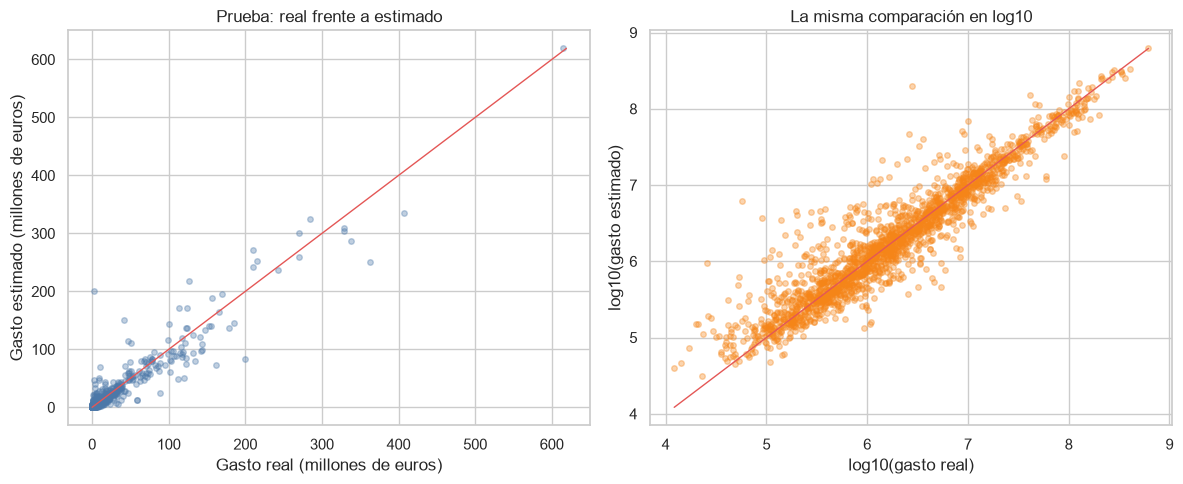

In [34]:
prediccion_test = modelo_final.predict(X_test)
metricas(y_test, prediccion_test, f"{mejor_nombre}, conjunto de prueba")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test / 1e6, prediccion_test / 1e6, alpha=0.35, s=16, color="#4C78A8")
limite = max(y_test.max(), prediccion_test.max()) / 1e6
axes[0].plot([0, limite], [0, limite], color="#E45756", linewidth=1)
axes[0].set_title("Prueba: real frente a estimado")
axes[0].set_xlabel("Gasto real (millones de euros)")
axes[0].set_ylabel("Gasto estimado (millones de euros)")

estimado_positivo = np.clip(prediccion_test, 0, None)
axes[1].scatter(np.log10(y_test), np.log10(estimado_positivo + 1), alpha=0.35, s=16, color="#F58518")
ejes = [
    min(np.log10(y_test).min(), np.log10(estimado_positivo + 1).min()),
    max(np.log10(y_test).max(), np.log10(estimado_positivo + 1).max()),
]
axes[1].plot(ejes, ejes, color="#E45756", linewidth=1)
axes[1].set_title("La misma comparación en log10")
axes[1].set_xlabel("log10(gasto real)")
axes[1].set_ylabel("log10(gasto estimado)")
plt.tight_layout()
plt.show()

La diagonal roja sería una predicción perfecta. En euros corrientes, los destinos de cientos de millones dominan el dibujo. En logaritmo se ve el resto de países: si la nube sigue la diagonal también ahí, el modelo no solo acierta el pelotón de cabeza.

### Comprobación temporal

En la partición anterior, un agosto de 2024 puede caer en el entrenamiento y un agosto de 2023 en la prueba. Eso es válido para comparar algoritmos, y es más fácil de lo que será el uso real. El uso real es anticipar meses posteriores.

Se reentrena el mismo tipo de modelo, con los mismos hiperparámetros, usando solo los años **2019-2024**, y se evalúa en **2025 y 2026** (hasta junio de 2026, que es el último mes del fichero). Esos meses no entran en este segundo entrenamiento.

In [35]:
X_tiempo = codificado.drop(columns=["gasto_turistico"])
y_tiempo = codificado["gasto_turistico"]
pasados = codificado["anio"] <= 2024

modelo_temporal = clone(modelo_final)
modelo_temporal.fit(X_tiempo.loc[pasados], y_tiempo.loc[pasados])
prediccion_futura = modelo_temporal.predict(X_tiempo.loc[~pasados])
metricas(
    y_tiempo.loc[~pasados],
    prediccion_futura,
    f"{mejor_nombre}, prueba temporal 2025-2026",
)
print("Filas de entrenamiento temporal:", int(pasados.sum()))
print("Filas de prueba temporal:", int((~pasados).sum()))

Bosque ajustado, prueba temporal 2025-2026
  RMSE:                      10,287,037 euros
  Error absoluto medio:       3,154,038 euros
  Error absoluto mediano:       444,582 euros
  R²:                             0.953
Filas de entrenamiento temporal: 7406
Filas de prueba temporal: 2115


## 7. Conclusiones

El proyecto cubre el recorrido completo: de la tabla oficial del INE a un modelo que estima el gasto turístico mensual de un destino.

- **Qué se predice y qué no.** El target es el gasto total del mes. El gasto con tarjeta duplica esa información (sale publicado a la vez y con una correlación cercana a 1) y el gasto medio diario describe otra cosa: en agosto el volumen sube y el gasto por día baja. Meter cualquiera de los dos como predictor no serviría para anticipar la cifra del INE.
- **Qué aprende el modelo.** País y mes bastan para situar el volumen, porque cada destino repite su estacionalidad. La regresión lineal solo puede sumar "efecto país + efecto mes" y, en destinos pequeños, llega a estimar un gasto negativo: un efecto de mes pensado para todos los países no cabe en una cifra de cien mil euros. El árbol y el bosque distinguen, por ejemplo, un agosto en un destino de playa de un agosto en un destino que no vive del verano, y se mantienen en cifras positivas. Por eso superan a la recta en la validación cruzada. El error de entrenamiento del árbol, mucho más bajo que el de validación, recuerda que un ajuste perfecto sobre los datos vistos no es el criterio de elección.
- **Cómo leer el RMSE.** El RMSE queda en millones de euros. No quiere decir que un destino mediano se equivoque en esa cantidad: la mediana del gasto mensual publicado está cerca de 1,5 millones y unos pocos países superan los cien millones en un solo mes. Esos casos grandes pesan más en el RMSE. El error absoluto mediano, impreso junto al RMSE, describe mejor el caso típico.
- **El corte temporal aguanta.** Entrenar hasta 2024 y evaluar 2025-2026 no empeora el resultado respecto a la partición aleatoria. El patrón país-mes es estable de un año para otro. Un árbol sin límite, en la práctica, se apoya en el año más reciente que ha visto para ese destino y ese mes; funciona aquí porque el gasto no da un salto brusco entre 2024 y 2025.
- **Límites.** Faltan muchos países-mes de 2020 y 2021, y 26 países no tienen ninguna cifra en todo el periodo: el modelo no puede inventar un destino que el INE nunca publica. La predicción aproxima la estadística oficial, no la sustituye, y no dice *por qué* crece un destino (renta, precios, una ruta aérea nueva). Tampoco separa número de viajeros y gasto por persona: ese desglose no está en la tabla.
- **La importancia de las variables**, en un bosque o en un árbol, es orientativa. Señala qué columnas usa el modelo para partir; no es un efecto causal.

Posibles ampliaciones, sin cambiar el target: incorporar el número de viajes o de pernoctaciones cuando se publique una tabla enlazable, y revisar los meses marcados como no publicados en lugar de tratarlos solo como ausencias.

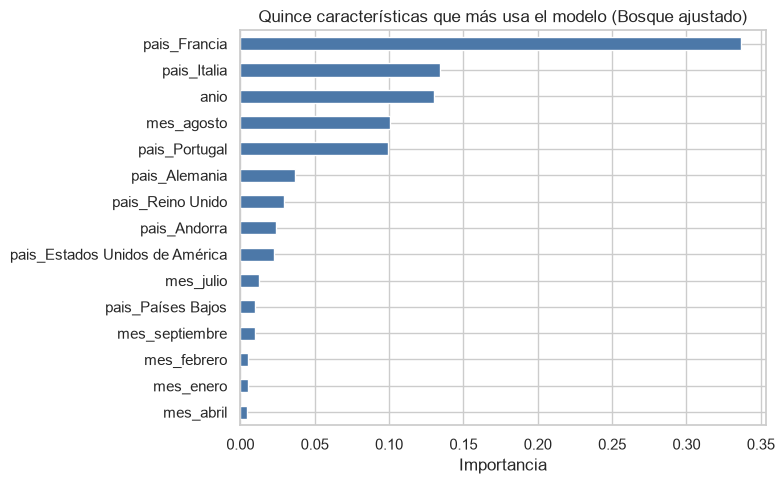

In [36]:
if hasattr(modelo_final, "feature_importances_"):
    importancias = (
        pd.Series(modelo_final.feature_importances_, index=X.columns)
        .sort_values(ascending=False)
        .head(15)
    )
    fig, ax = plt.subplots(figsize=(8, 5))
    importancias.sort_values().plot(kind="barh", color="#4C78A8", ax=ax)
    ax.set_title(f"Quince características que más usa el modelo ({mejor_nombre})")
    ax.set_xlabel("Importancia")
    plt.tight_layout()
    plt.show()
else:
    print("El modelo elegido no expone importancia de características.")

### Predicción de meses nuevos

Con el modelo ya elegido y evaluado se pueden estimar meses que no están en la tabla. No hay cifra real con la que contrastar: son escenarios.

Se piden tres destinos en 2027, cada uno en un mes de comportamiento distinto (verano, invierno e inicio de la temporada de invierno). Para leer el resultado con contexto, debajo se imprime lo que el INE publicó en ese mismo país y ese mismo mes durante los últimos años disponibles.

In [37]:
escenarios = pd.DataFrame({
    "pais": ["Portugal", "Japón", "Marruecos"],
    "mes": ["agosto", "febrero", "diciembre"],
    "anio": [2027, 2027, 2027],
})

plantilla = modelo[["pais", "mes", "anio"]]
junto = pd.concat([plantilla, escenarios], ignore_index=True)
dummies_junto = pd.get_dummies(junto, columns=["pais", "mes"], dtype=int)
X_nuevos = dummies_junto.iloc[-len(escenarios):].reindex(columns=X.columns, fill_value=0)

escenarios = escenarios.copy()
escenarios["gasto_estimado"] = modelo_final.predict(X_nuevos)
escenarios["gasto_estimado"] = escenarios["gasto_estimado"].round(0)
escenarios

,pais,mes,anio,gasto_estimado
0,Portugal,agosto,2027,507990149.0
1,Japón,febrero,2027,11804605.0
2,Marruecos,diciembre,2027,28356474.0


In [38]:
historico = gasto.dropna(subset=["gasto_turistico"]).copy()
historico["mes"] = historico["mes_nombre"]
consulta = historico[
    ((historico["pais"] == "Portugal") & (historico["mes"] == "agosto"))
    | ((historico["pais"] == "Japón") & (historico["mes"] == "febrero"))
    | ((historico["pais"] == "Marruecos") & (historico["mes"] == "diciembre"))
]
consulta.pivot_table(index="anio", columns="pais", values="gasto_turistico", aggfunc="first")

pais,Japón,Marruecos,Portugal
anio,,,
2019,3651113.0,11776205.0,379088938.0
2020,4019783.0,NaN,109220707.0
2021,NaN,3492790.0,195625682.0
2022,223018.0,20183419.0,417309052.0
2023,1987040.0,14125468.0,499620140.0
2024,5379932.0,21489825.0,498460910.0
2025,9790301.0,27170147.0,514723983.0
2026,10308633.0,NaN,NaN


La predicción de 2027 hay que leerla como una prolongación del patrón ya visto, no como un dato del INE. El bosque deja agosto en Portugal cerca de 508 millones de euros (agosto de 2025 fue de unos 515), febrero en Japón cerca de 12 millones (febrero de 2026 fue de unos 10) y diciembre en Marruecos cerca de 28 millones (diciembre de 2025 fue de unos 27). Si el modelo elegido es un árbol o un bosque, un año posterior al último de la muestra cae en la misma rama que el año más reciente: la cifra se parece al último agosto, febrero o diciembre observado de ese país. Tiene sentido mientras el destino no cambie de régimen. Una huelga aérea, un cambio de divisa o un mundial de fútbol no están en las variables y el modelo no los va a anticipar.

## Entrega

- Enlace al cuaderno compartido en Google Colab, en modo lectura: *(pegar aquí)*
- Vídeo explicativo de YouTube: *(pegar aquí)*